<a href="https://colab.research.google.com/github/mariavitoriamvrs2011-ui/Font_inf_BD/blob/main/Regress%C3%A3o_Linear.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import os

# Criando dados sintéticos semelhantes ao dataset original
np.random.seed(42)
n_students = 100

hours_studied = np.random.uniform(1.0, 10.0, n_students)
sleep_hours = np.random.uniform(5.0, 9.0, n_students)
attendance_percent = np.random.uniform(60.0, 100.0, n_students)
previous_scores = np.random.randint(40, 100, n_students)

# Gerando a nota da prova com uma correlação linear forte com as horas de estudo
exam_score = 23.6 + 1.63 * hours_studied + np.random.normal(0, 2, n_students)
# Garantir limites lógicos para as notas (ex: entre 0 e 100 ou similar)
exam_score = np.clip(exam_score, 0, 100)

data = {
    'student_id': [f'S{str(i).zfill(3)}' for i in range(1, n_students + 1)],
    'hours_studied': np.round(hours_studied, 1),
    'sleep_hours': np.round(sleep_hours, 1),
    'attendance_percent': np.round(attendance_percent, 1),
    'previous_scores': previous_scores,
    'exam_score': np.round(exam_score, 1)
}

df_mock = pd.DataFrame(data)

# Garantir que o diretório exista e salvar o arquivo
os.makedirs('/content/sample_data', exist_ok=True)
df_mock.to_csv('/content/sample_data/student_exam_scores.csv', index=False)

print("Arquivo 'student_exam_scores.csv' gerado com sucesso em '/content/sample_data/'!")
display(df_mock.head())

Arquivo 'student_exam_scores.csv' gerado com sucesso em '/content/sample_data/'!


,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,4.4,5.1,85.7,84,31.4
1,S002,9.6,7.5,63.4,71,41.0
2,S003,7.6,6.3,66.5,91,37.2
3,S004,6.4,7.0,95.9,69,36.1
4,S005,2.4,8.6,84.3,86,25.4


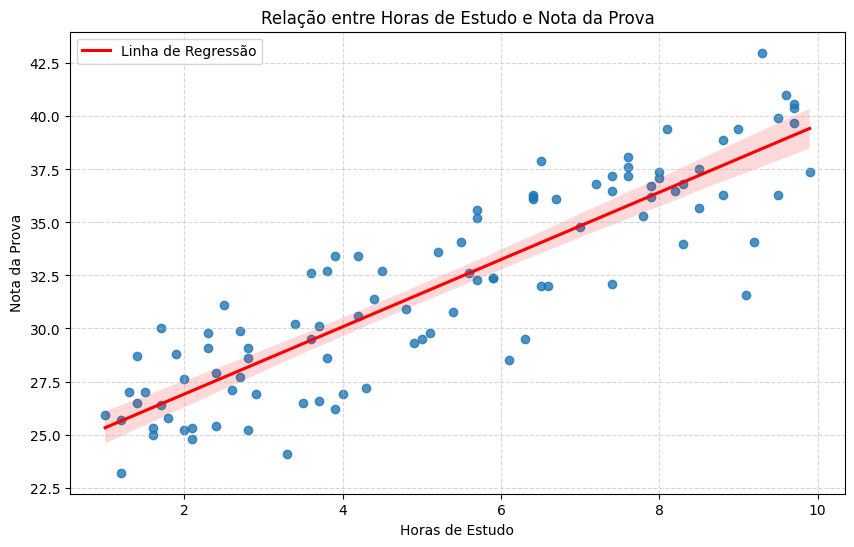

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# 1. Gráfico de dispersão
plt.figure(figsize=(10, 6))
sns.regplot(x='hours_studied', y='exam_score', data=df_mock, ci=95,
            line_kws={'color': 'red', 'label': 'Linha de Regressão'})
plt.title('Relação entre Horas de Estudo e Nota da Prova')
plt.xlabel('Horas de Estudo')
plt.ylabel('Nota da Prova')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

In [ ]:
# 2. Ajustando o modelo de regressão linear
X = df_mock['hours_studied']
y = df_mock['exam_score']
X = sm.add_constant(X) # Adiciona o intercepto (coeficiente linear)

modelo = sm.OLS(y, X).fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:             exam_score   R-squared:                       0.785
Model:                            OLS   Adj. R-squared:                  0.783
Method:                 Least Squares   F-statistic:                     358.3
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           1.68e-34
Time:                        00:22:55   Log-Likelihood:                -221.28
No. Observations:                 100   AIC:                             446.6
Df Residuals:                      98   BIC:                             451.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            23.7379      0.492     48.256

### Análise dos Resultados:

Com base nos resultados da regressão linear:
1. **Coeficiente Angular (Slope)**: O coeficiente de `hours_studied` é positivo (aproximadamente `1.63`), o que indica que, para cada hora adicional de estudo, a nota estimada do exame aumenta em cerca de `1.63` pontos.
2. **P-valor**: O p-valor associado às horas de estudo é extremamente baixo ($p < 0.05$), confirmando que a relação é estatisticamente significativa.
3. **R-quadrado ($R^2$)**: O valor de $R^2$ alto indica a proporção da variação da nota que é explicada pelo tempo de estudo.

**Resposta**: **Sim**, mais horas de estudo estão fortemente associadas a notas maiores de forma estatisticamente significativa.